# 02 - Overfitting and regularisation
Wine Quality dataset (red and white wines), regression of the quality score

With only 5,320 wines, a big network can memorise the training data. In this notebook we take a
network that is clearly too big (256-128-64 neurons, about 45,000 parameters) and we compare
different ways of controlling overfitting:

1. No regularisation (200 epochs, the model of the last epoch is kept)
2. Early stopping (patience of 20 epochs on the validation loss)
3. Early stopping + dropout (30%)
4. Early stopping + weight decay (L2 penalty, 0.001)
5. Early stopping + batch normalisation

We use the same 5 outer folds as in the ML report and in notebook 01.

In [1]:
import warnings
warnings.filterwarnings("ignore")

import copy
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import torch
from torch import nn
from sklearn.model_selection import KFold, StratifiedKFold, train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import mean_squared_error, r2_score, f1_score, accuracy_score

from utils import *

set_style()
torch.set_num_threads(4)
np.random.seed(SEED)
torch.manual_seed(SEED)

def rmse(a, b):
    return np.sqrt(mean_squared_error(a, b))

In [2]:
wine = load_wine()
X = wine[FEATURES].to_numpy()
y = wine["quality"].to_numpy().astype(float)

HIDDEN = (256, 128, 64)
print("Parameters of the big network:", count_parameters(MLP(X.shape[1], HIDDEN)))

CONFIGS = {
    "No regularisation":       dict(dropout=0.0, weight_decay=0.0, batch_norm=False, patience=None),
    "Early stopping":          dict(dropout=0.0, weight_decay=0.0, batch_norm=False, patience=20),
    "ES + dropout (0.3)":      dict(dropout=0.3, weight_decay=0.0, batch_norm=False, patience=20),
    "ES + weight decay (1e-3)": dict(dropout=0.0, weight_decay=1e-3, batch_norm=False, patience=20),
    "ES + batch norm":         dict(dropout=0.0, weight_decay=0.0, batch_norm=True, patience=20),
}

mse = nn.MSELoss()
def reg_loss(out, yb):
    return mse(out.squeeze(1), yb)

Parameters of the big network: 44545


## 1. Training with each configuration

In [3]:
outer = KFold(n_splits=5, shuffle=True, random_state=SEED)
rows, curves = [], {}

for fold, (train_idx, test_idx) in enumerate(outer.split(X), start=1):
    tr, val = train_test_split(train_idx, test_size=0.15, random_state=SEED)
    scaler = StandardScaler().fit(X[tr])
    y_mean, y_std = y[tr].mean(), y[tr].std()
    Xtr, Xval, Xte = (to_tensor(scaler.transform(X[i])) for i in (tr, val, test_idx))
    ytr, yval = (to_tensor((y[i] - y_mean) / y_std) for i in (tr, val))

    for name, cfg in CONFIGS.items():
        torch.manual_seed(SEED)
        model = MLP(X.shape[1], HIDDEN, 1, cfg["dropout"], cfg["batch_norm"])
        hist = train_model(model, Xtr, (ytr,), Xval, (yval,), reg_loss, weight_decay=cfg["weight_decay"],
                           max_epochs=200, patience=cfg["patience"])
        model.eval()
        with torch.no_grad():
            pred_tr = model(Xtr).squeeze(1).numpy() * y_std + y_mean
            pred_te = model(Xte).squeeze(1).numpy() * y_std + y_mean
        rows.append({"fold": fold, "config": name, "epochs": len(hist["train"]),
                     "train RMSE": rmse(y[tr], pred_tr), "test RMSE": rmse(y[test_idx], pred_te),
                     "test R2": r2_score(y[test_idx], pred_te)})
        if fold == 1:
            curves[name] = hist
    print(f"fold {fold} done")

folds = pd.DataFrame(rows)
summary = (folds.groupby("config", sort=False)
                .agg(train_RMSE=("train RMSE", "mean"), test_RMSE=("test RMSE", "mean"),
                     test_RMSE_std=("test RMSE", "std"), test_R2=("test R2", "mean"),
                     epochs=("epochs", "mean")))
summary["gap"] = summary["test_RMSE"] - summary["train_RMSE"]
folds.to_csv(RES_DIR / "regularisation_folds.csv", index=False)
summary.to_csv(RES_DIR / "regularisation_summary.csv")
summary.round(3)

fold 1 done


fold 2 done


fold 3 done


fold 4 done


fold 5 done


,train_RMSE,test_RMSE,test_RMSE_std,test_R2,epochs,gap
config,,,,,,
No regularisation,0.139,0.845,0.016,0.074,200.0,0.706
Early stopping,0.654,0.699,0.022,0.367,28.4,0.045
ES + dropout (0.3),0.640,0.696,0.019,0.372,47.0,0.056
ES + weight decay (1e-3),0.640,0.697,0.018,0.371,33.6,0.056
ES + batch norm,0.632,0.697,0.017,0.371,26.4,0.065


## 2. Learning curves (fold 1)

Without regularisation the training loss keeps going down, but after a few epochs the validation
loss starts to go up: the network is memorising the training wines.

Figure saved -> ../results/figures/reg_learning_curves_overfitting.png


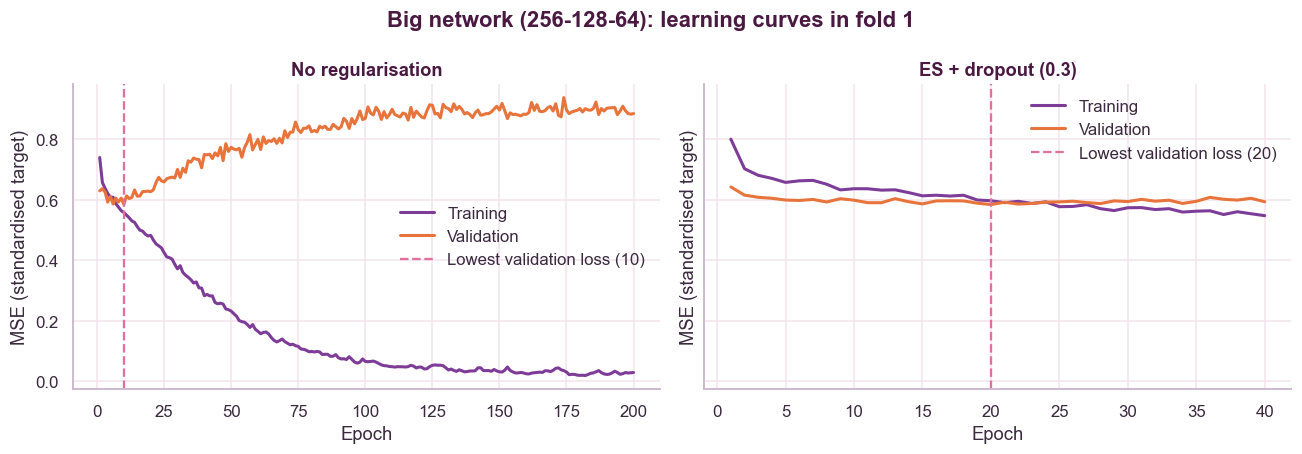

In [4]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4.2), sharey=True)
for ax, name in zip(axes, ["No regularisation", "ES + dropout (0.3)"]):
    h = curves[name]
    ax.plot(range(1, len(h["train"]) + 1), h["train"], color=PURPLE, lw=2, label="Training")
    ax.plot(range(1, len(h["val"]) + 1), h["val"], color=ORANGE, lw=2, label="Validation")
    ax.axvline(h["best_epoch"], color=PINK, ls="--", lw=1.5, label=f"Lowest validation loss ({h['best_epoch']})")
    ax.set_title(name)
    ax.set_xlabel("Epoch")
    ax.set_ylabel("MSE (standardised target)")
    ax.legend()
fig.suptitle("Big network (256-128-64): learning curves in fold 1", color=PLUM, fontweight="semibold")
fig.tight_layout()
save(fig, "reg_learning_curves_overfitting.png")
plt.show()

## 3. Training vs test error

The difference between the two bars shows how much the network overfits.

Figure saved -> ../results/figures/reg_regularisation_rmse.png


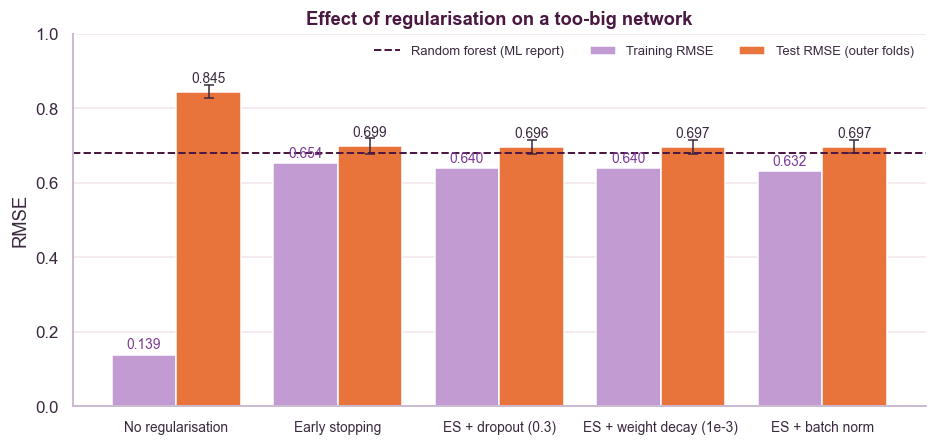

In [5]:
fig, ax = plt.subplots(figsize=(10, 4.4))
pos = np.arange(len(summary))
ax.bar(pos - 0.2, summary["train_RMSE"], 0.4, color=LILAC, label="Training RMSE")
ax.bar(pos + 0.2, summary["test_RMSE"], 0.4, yerr=summary["test_RMSE_std"], color=ORANGE,
       error_kw=dict(ecolor=INK, lw=1, capsize=3), label="Test RMSE (outer folds)")
for p, v in zip(pos, summary["test_RMSE"]):
    ax.text(p + 0.2, v + 0.025, f"{v:.3f}", ha="center", fontsize=9)
ax.axhline(0.680, color=PLUM, ls="--", lw=1.3, label="Random forest (ML report)")
ax.set_xticks(pos)
ax.set_xticklabels(summary.index, fontsize=9)
ax.set_ylabel("RMSE")
for p, v in zip(pos, summary["train_RMSE"]):
    ax.text(p - 0.2, v + 0.015, f"{v:.3f}", ha="center", fontsize=9, color=PURPLE)
ax.set_ylim(0, 1.0)
ax.set_title("Effect of regularisation on a too-big network")
ax.legend(loc="upper right", ncol=3, fontsize=8.5)
ax.grid(axis="x", visible=False)
save(fig, "reg_regularisation_rmse.png")
plt.show()

## Summary

* Without any regularisation the big network overfits a lot: the training error is very low but
  the test error is the worst of all the configurations.
* Early stopping alone already removes most of the problem. Dropout, weight decay and batch norm on
  top of it give similar results; none of them makes the network better than the random forest.